# PID control of a DC motor

A small DC motor, a discrete PI speed controller and the things that make
control interesting in practice: a voltage limit with integrator windup, a
load torque, and stability margins. The motor is continuous
(`ContinuousLTI`), the controller discrete at 10 kHz, as in a
microcontroller. Every loop is checked against the exact discrete theory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 10e3  # controller rate / Hz
T = 1 / fs

## 1. The motor

Armature voltage $v$ drives a current $i$ through resistance $R$ and
inductance $L$; the current makes torque $K i$ on inertia $J$ with friction
$b$; the speed $\omega$ induces the back EMF $K\omega$:

$$L \dot i = v - R i - K\omega, \qquad J\dot\omega = K i - b\omega - \tau_\mathrm{load}$$

From voltage to speed, $G(s) = \dfrac{K}{(Js + b)(Ls + R) + K^2}$: two poles,
an electrical one (about $L/R$ = 0.5 ms) and a mechanical one ($JR/K^2$ =
8 ms). A step of 1 V settles at $K / (bR + K^2)$ ≈ 19.9 rad/s.

poles: [-1865.98671662  -134.51328338] 1/s, mechanical time constant 8.0 ms


max |error| vs scipy zoh: 5.0e-13 rad/s
after 50 ms 19.89 rad/s, final value 19.92


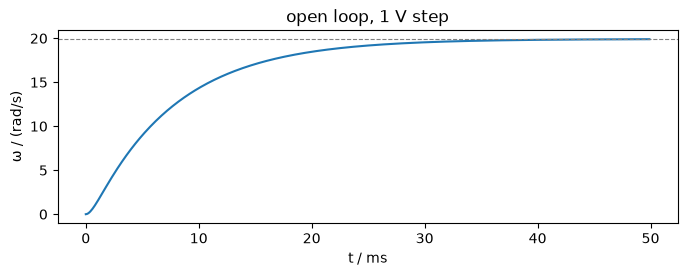

In [2]:
R, L, K, J, b = 1.0, 0.5e-3, 0.05, 2e-5, 1e-5  # ohm, henry, N m/A, kg m^2, N m s
num, den = [K], [J * L, J * R + b * L, b * R + K**2]
tau_m = J * R / K**2
dc_gain = K / (b * R + K**2)
print(f"poles: {np.roots(den).real} 1/s, mechanical time constant {1e3 * tau_m:.1f} ms")

motor = sl.ContinuousLTI(num, den, name="motor")
speed = sl.Scope("speed")
sl.Step(0.0, name="1 V") >> motor >> speed
d = sl.Diagram(speed, fs=fs)
d.run(0.05)

# reference: the motor discretised for held inputs, by scipy
nd, dd, _ = sig.cont2discrete((num, den), T, "zoh")
ref = sig.lfilter(np.squeeze(nd), dd, np.ones(d.n))
print(f"max |error| vs scipy zoh: {np.max(np.abs(speed.data - ref)):.1e} rad/s")
print(f"after 50 ms {speed.data[-1]:.2f} rad/s, final value {dc_gain:.2f}")

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * d.t, speed.data)
ax.axhline(dc_gain, ls="--", c="gray", lw=0.8)
ax.set(xlabel="t / ms", ylabel="ω / (rad/s)", title="open loop, 1 V step")
plt.show()

## 2. A PI speed loop

The PI controller $u[n] = k_p e[n] + k_i T \sum_{m \le n} e[m]$ is an `IIR`
with $b = (k_p + k_i T,\ -k_p)$, $a = (1, -1)$. Choosing
$k_i = k_p / \tau_m$ cancels the mechanical pole; the loop is then about
$1/(\tau s (\tau_e s + 1))$ with $\tau = \tau_m / (k_p G(0))$, critically
damped for $\tau = 4\tau_e$, here $k_p \approx 0.2$ V/(rad/s).

The motor's output depends on inputs up to the sample before, so the loop
needs no extra delay. It runs sample by sample, compiled with numba.

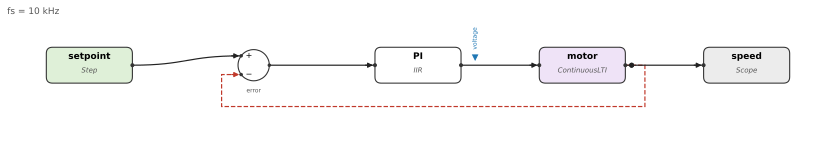

In [3]:
def speed_loop(kp, setpoint=100.0, controller=None, load=None):
    # setpoint -> error -> controller -> motor -> speed, fed back
    ref, err = sl.Step(0.0, after=setpoint, name="setpoint"), sl.Sum("+-", name="error")
    if controller is None:
        controller = sl.IIR(b=[kp + kp / tau_m * T, -kp], a=[1.0, -1.0], name="PI")
    plant = sl.ContinuousLTI(num, den, name="motor")
    w = sl.Scope("speed")
    ref >> err["x0"]
    err >> controller >> plant
    if load is None:
        plant >> w
    else:  # a load torque slows the motor through its own transfer function
        total = sl.Sum("++", name="speed")
        plant >> total["x0"]
        load >> sl.ContinuousLTI([-L, -R], den, name="load path") >> total["x1"]
        total >> w
    w_in = total if load is not None else plant
    w_in >> err["x1"]
    d = sl.Diagram(w, fs=fs)
    u = d.probe(controller, name="voltage")
    return d, w, u


d, w, u = speed_loop(0.2)
d

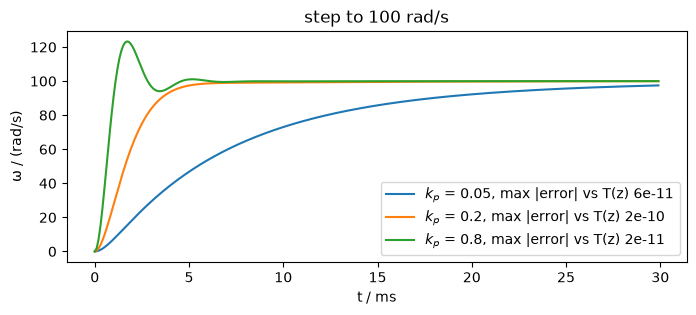

In [4]:
def closed_loop(kp, n, setpoint=100.0):
    # T(z) = C P / (1 + C P) from coefficients in z^-1
    c_b, c_a = [kp + kp / tau_m * T, -kp], [1.0, -1.0]
    p_b, p_a = np.squeeze(nd), dd
    lb, la = np.convolve(c_b, p_b), np.convolve(c_a, p_a)
    return sig.lfilter(lb, la + lb, setpoint * np.ones(n))


fig, ax = plt.subplots(figsize=(8, 3))
for kp in (0.05, 0.2, 0.8):
    d, w, u = speed_loop(kp)
    d.run(0.03)
    err = np.max(np.abs(w.data - closed_loop(kp, d.n)))
    ax.plot(1e3 * d.t, w.data, label=f"$k_p$ = {kp}, max |error| vs T(z) {err:.0e}")
ax.set(xlabel="t / ms", ylabel="ω / (rad/s)", title="step to 100 rad/s")
ax.legend()
plt.show()

Small $k_p$ is slow, large $k_p$ overshoots: the electrical pole, ignored
in the design, matters once the loop gets fast. Each run matches $T(z)$ to
rounding.

## 3. A voltage limit and integrator windup

The driver gives at most 12 V. A step to 200 rad/s (10 V in steady state)
asks for 40 V at first: the voltage saturates, the speed rises slower than
the controller expects, and the integrator keeps summing the large error.
When the speed arrives, the integrator holds far too much and the speed
overshoots.

Clamping stops the integrator while the output is limited. It is a few
lines of scalar Python with an `if`: a `FuncSingle` with the integrator as
its state.

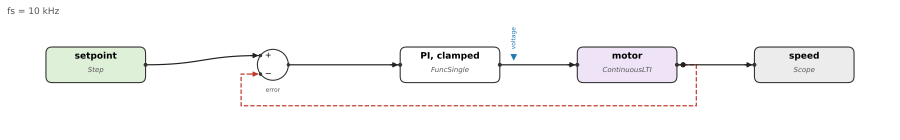

In [5]:
kp, ki, umax = 0.2, 0.2 / tau_m, 12.0


def pi_clamped(e, s, kp=kp, ki=ki, T=T, umax=umax):
    # PI with clamping anti-windup; s is the integral term
    s_new = s + ki * T * e
    u = kp * e + s_new
    if u > umax:
        return umax, s  # saturated: keep the integral
    if u < -umax:
        return -umax, s
    return u, s_new


windup = sl.Subsystem(
    inputs={"x": (pi := sl.IIR(b=[kp + ki * T, -kp], a=[1.0, -1.0], name="PI"))},
    outputs={"y": pi >> sl.FuncChunk(lambda u, m=umax: np.clip(u, -m, m), name="limit")},
    name="PI, limited",
)
clamped = sl.FuncSingle(pi_clamped, state=0.0, name="PI, clamped")
runs = {}
for name, ctrl in (("windup", windup), ("clamping", clamped)):
    d, w, u = speed_loop(kp, setpoint=200.0, controller=ctrl)
    d.run(0.04)
    runs[name] = (d, w, u)
runs["clamping"][0]

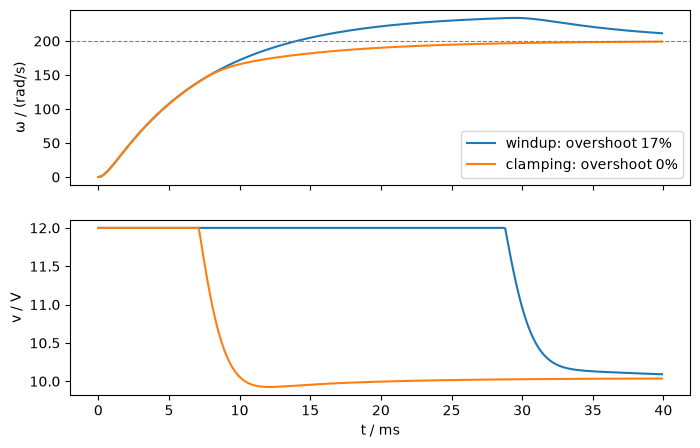

unsaturated: max |IIR - FuncSingle| = 4.3e-14 rad/s


In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for name, (d, w, u) in runs.items():
    a1.plot(1e3 * d.t, w.data, label=f"{name}: overshoot {max(w.data.max() / 200 - 1, 0):.0%}")
    a2.plot(1e3 * d.t, u.data, label=name)
a1.axhline(200, ls="--", c="gray", lw=0.8)
a1.set(ylabel="ω / (rad/s)")
a1.legend()
a2.set(xlabel="t / ms", ylabel="v / V")
plt.show()

# without saturation, the clamped PI is the same controller as the IIR
d1, w1, _ = speed_loop(kp)
d2, w2, _ = speed_loop(kp, controller=sl.FuncSingle(pi_clamped, state=0.0, params={"umax": 1e9}))
d1.run(0.02)
d2.run(0.02)
print(f"unsaturated: max |IIR - FuncSingle| = {np.max(np.abs(w1.data - w2.data)):.1e} rad/s")

## 4. A load torque

At 30 ms a load of 5 mN m grabs the shaft. By superposition it acts
through its own transfer function, from torque to speed
$-(Ls + R)/((Js + b)(Ls + R) + K^2)$. Without control the speed would drop
by $\tau R / (bR + K^2)$ ≈ 2 rad/s for good; the integrator pulls it back
to the set point.

open-loop drop would be 1.99 rad/s; closed loop: largest dip 0.41 rad/s, final 99.983 rad/s


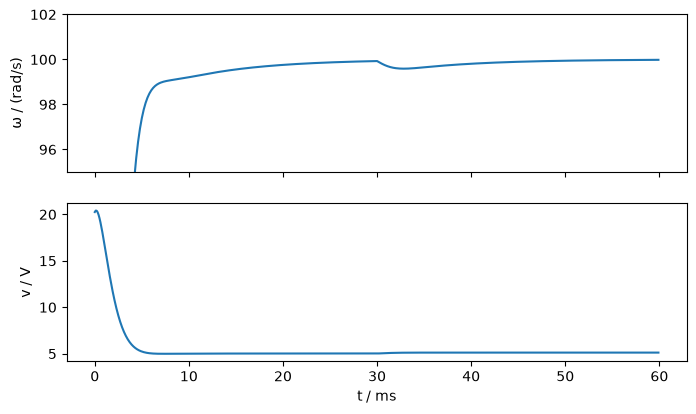

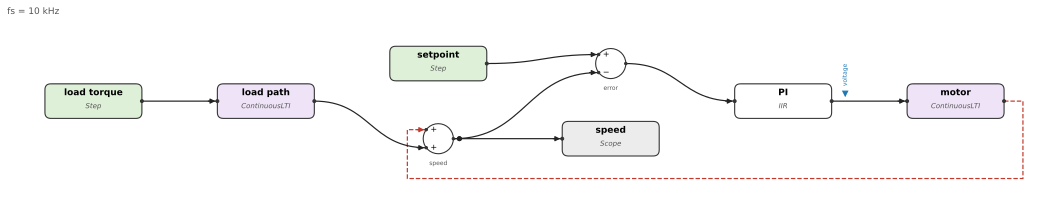

In [7]:
load = sl.Step(0.03, after=5e-3, name="load torque")
d, w, u = speed_loop(0.2, load=load)
d.run(0.06)
drop = 5e-3 * R / (b * R + K**2)
print(f"open-loop drop would be {drop:.2f} rad/s; closed loop: largest dip "
      f"{100 - w.data[d.t > 0.03].min():.2f} rad/s, final {w.data[-1]:.3f} rad/s")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
a1.plot(1e3 * d.t, w.data)
a1.set(ylabel="ω / (rad/s)", ylim=(95, 102))
a2.plot(1e3 * d.t, u.data)
a2.set(xlabel="t / ms", ylabel="v / V")
plt.show()
d

## 5. Stability margins

The loop gain $L(z) = C(z) P(z)$ on the unit circle gives the phase margin
at the gain crossover. A sweep over $k_p$ shows the textbook link: less
phase margin, more overshoot.

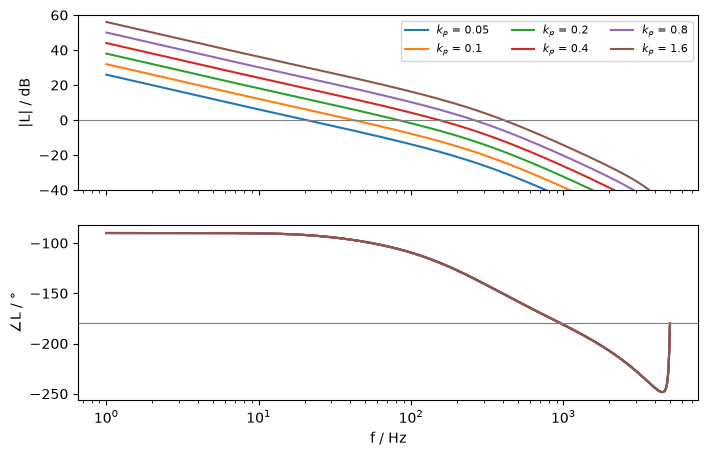

  kp   crossover   phase margin   overshoot
 0.05       21 Hz        87.9 °        0.0%
 0.10       42 Hz        83.0 °        0.0%
 0.20       82 Hz        74.1 °        0.0%
 0.40      152 Hz        60.7 °        7.4%
 0.80      258 Hz        44.7 °       23.3%
 1.60      405 Hz        29.2 °       42.5%


In [8]:
def margins(kp):
    c_b, c_a = [kp + kp / tau_m * T, -kp], [1.0, -1.0]
    f = np.logspace(0, np.log10(fs / 2), 4000)
    _, C = sig.freqz(c_b, c_a, worN=f, fs=fs)
    _, P = sig.freqz(np.squeeze(nd), dd, worN=f, fs=fs)
    Lg = C * P
    i = np.argmin(np.abs(np.abs(Lg) - 1))
    return f, Lg, f[i], 180 + np.degrees(np.angle(Lg[i]))


rows = []
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for kp in (0.05, 0.1, 0.2, 0.4, 0.8, 1.6):
    f, Lg, fc, pm = margins(kp)
    d, w, _ = speed_loop(kp)
    d.run(0.2)
    rows.append((kp, fc, pm, max(w.data.max() / 100 - 1, 0)))
    a1.semilogx(f, 20 * np.log10(np.abs(Lg)), label=f"$k_p$ = {kp}")
    a2.semilogx(f, np.degrees(np.unwrap(np.angle(Lg))))
a1.axhline(0, c="gray", lw=0.8)
a1.set(ylabel="|L| / dB", ylim=(-40, 60))
a1.legend(fontsize=8, ncol=3)
a2.axhline(-180, c="gray", lw=0.8)
a2.set(xlabel="f / Hz", ylabel="∠L / °")
plt.show()

print("  kp   crossover   phase margin   overshoot")
for kp, fc, pm, ov in rows:
    print(f"{kp:5.2f}  {fc:7.0f} Hz   {pm:9.1f} °    {ov:8.1%}")

## Summary

- Plants are `ContinuousLTI` (or `ODE`); controllers are discrete blocks:
  `IIR` for linear ones, `FuncSingle` for logic such as anti-windup.
- Loops through continuous blocks need no extra delay and compile with
  numba; they match the exact discrete theory.
- Saturation, disturbances and gain sweeps are a few lines each: probes, a
  second input, a `for` loop.